In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [5]:
def w_norm_per_xbin(h,x,y):
    w = np.empty([len(x)-1,len(y)-1])
    for i in range(0,len(x)-1):
        for j in range(0,len(y)-1):
            w[i][j] = h[i][j]/sum(h[i]) + 10**-50
    return w

In [6]:
import math
def weighted_avg_and_std(values, weights):
    """
    Return the weighted average and standard deviation.

    values, weights -- Numpy ndarrays with the same shape.
    """
    average = np.average(values, weights=weights)
    # Fast and numerically precise:
    variance = np.average((values-average)**2, weights=weights)
    return (average, math.sqrt(variance))

In [7]:
observables1 = ['pt','b','m','n','w','reject','pt1','pt2','qlead','qsublead','y1','y2','phi1','phi2','nef']
observabless1 = ['pts','bs','ms','ns','ws','rejects','pt1s','pt2s','qleads','qsubleads','y1s','y2s','phi1s','phi2s', 'nefs']

PYTHIA6+GEANT

In [8]:
df = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_final.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and bs!=0 and reject<=0 and rejects<=0')

In [9]:
distance1 = []
distance2 = []
for i in range(0,df.shape[0]):
    phi1small = min(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi1large = max(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi2small = min(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    phi2large = max(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df.iloc[i]['phi1'], df.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df.iloc[i]['y1']-df.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df.iloc[i]['y2']-df.iloc[i]['y2s'])**2))
df['distance1'] = distance1
df['distance2'] = distance2

In [10]:
df_match = applyCut(df, 'pt>5 and b!=-9 and b!=0 and distance1 < 0.02 and distance2 < 0.02')

In [11]:
df_match = applyCut(df_match, 'not (pts>25 and w>4e-9)') # removes one high weight jet

In [54]:
df_match.eval('dpt_pt = (pts-pt)/pt', inplace=True)
df_match.eval('dpt = pts-pt', inplace=True)
df_match.eval('dpt1 = pt1s-pt1', inplace=True)
df_match.eval('dpt2 = pt2s-pt2', inplace=True)
df_match.eval('dpt_dihadron = dpt1+dpt2', inplace=True)
df_match.eval('spt_dihadron = pt1+pt2', inplace=True)

In [13]:
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

detector-level pT bin: 0


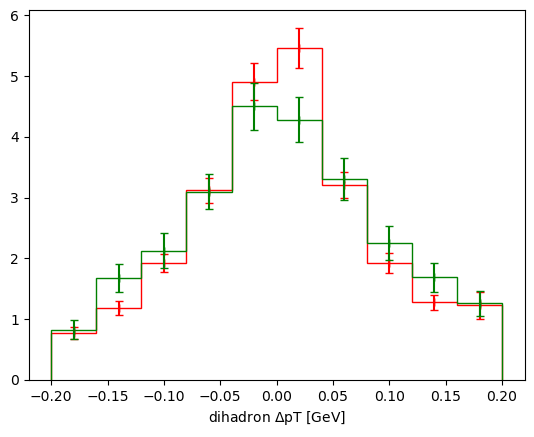

detector-level pT bin: 1


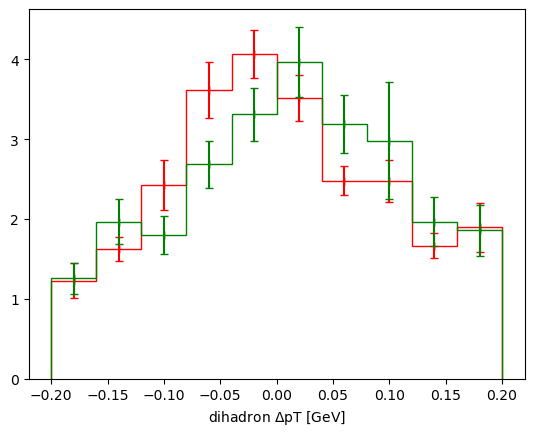

detector-level pT bin: 2


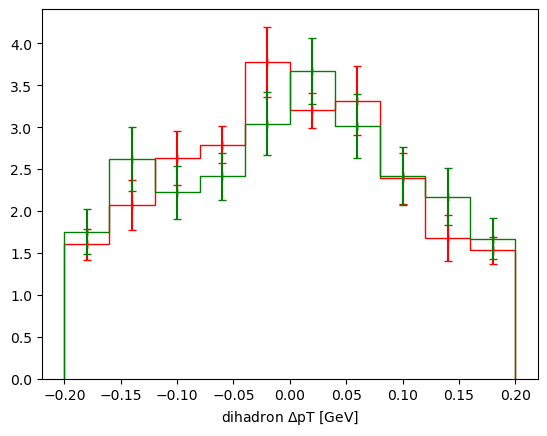

detector-level pT bin: 3


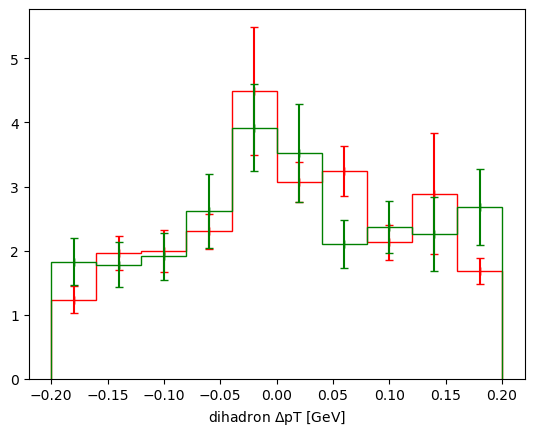

In [14]:
dpt_dihadron_array_os = []
sigma_dpt_dihadron_array_os = []
dpt_dihadron_array_ss = []
sigma_dpt_dihadron_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs==1')
    dpt_dihadron_os, sigma_dpt_dihadron_os = weighted_avg_and_std(df_temp_os['dpt_dihadron'], df_temp_os['w'])
    dpt_dihadron_ss, sigma_dpt_dihadron_ss = weighted_avg_and_std(df_temp_ss['dpt_dihadron'], df_temp_ss['w'])
    dpt_dihadron_array_os.append(dpt_dihadron_os)
    sigma_dpt_dihadron_array_os.append(sigma_dpt_dihadron_os)
    dpt_dihadron_array_ss.append(dpt_dihadron_ss)
    sigma_dpt_dihadron_array_ss.append(sigma_dpt_dihadron_ss)
    y_temp_os, yerr_temp_os, x = calc_hist(df_temp_os['dpt_dihadron'], weights=df_temp_os['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    y_temp_ss, yerr_temp_ss, x = calc_hist(df_temp_ss['dpt_dihadron'], weights=df_temp_ss['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('detector-level pT bin:', i)
    plt.hist(df_temp_os['dpt_dihadron'], weights=df_temp_os['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.hist(df_temp_ss['dpt_dihadron'], weights=df_temp_ss['w'], color='g', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_os/sum(y_temp_os), xerr=0, yerr=25*yerr_temp_os/sum(y_temp_os), color='r',ls='none',capsize=3)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_ss/sum(y_temp_ss), xerr=0, yerr=25*yerr_temp_ss/sum(y_temp_ss), color='g',ls='none',capsize=3)
    plt.xlabel('dihadron $\Delta$pT [GeV]')
    plt.ylim(bottom=0)
    plt.show()

In [17]:
err_on_mean_os = []
for j in range(0,4):
    df = applyCut(df_match_pts_array[j], 'bs==-1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_dihadron'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_os.append(err2)

In [18]:
err_on_mean_ss = []
for j in range(0,4):
    df = applyCut(df_match_pts_array[j], 'bs==1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_dihadron'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_ss.append(err2)

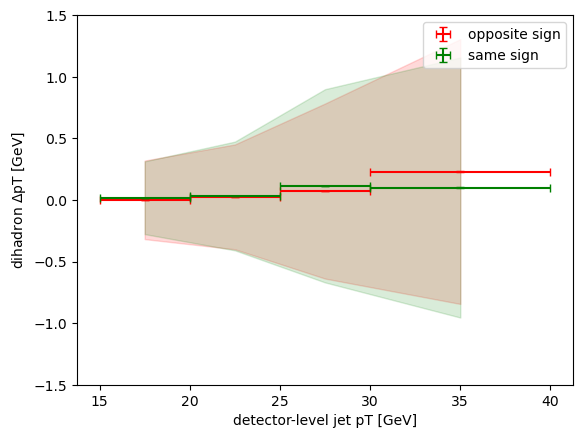

In [19]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_dihadron_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_dihadron_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_ss, color='g', label='same sign', ls='none', capsize=3)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_dihadron_array_os)-np.array(sigma_dpt_dihadron_array_os), np.array(dpt_dihadron_array_os)+np.array(sigma_dpt_dihadron_array_os), color='r', alpha=0.15)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_dihadron_array_ss)-np.array(sigma_dpt_dihadron_array_ss), np.array(dpt_dihadron_array_ss)+np.array(sigma_dpt_dihadron_array_ss), color='g', alpha=0.15)
plt.xlabel('detector-level jet pT [GeV]')
plt.ylabel('dihadron $\Delta$pT [GeV]')
plt.ylim(-1.5,1.5)
plt.legend()

detector-level pT bin: 0


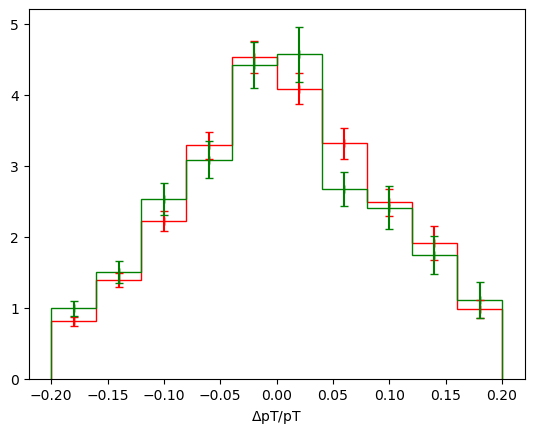

detector-level pT bin: 1


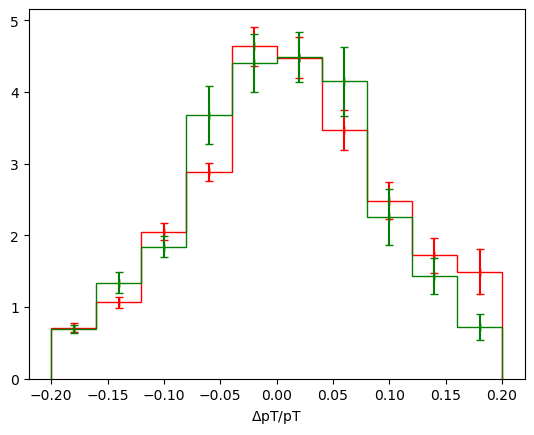

detector-level pT bin: 2


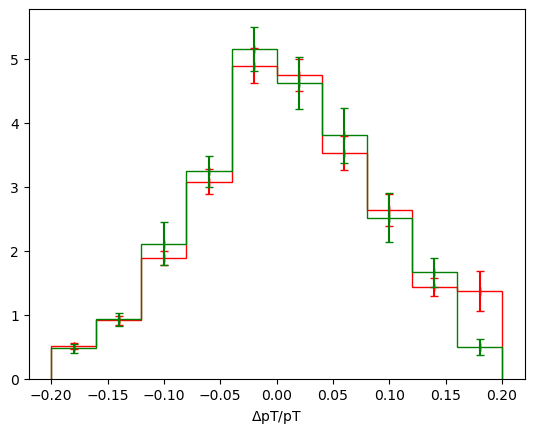

detector-level pT bin: 3


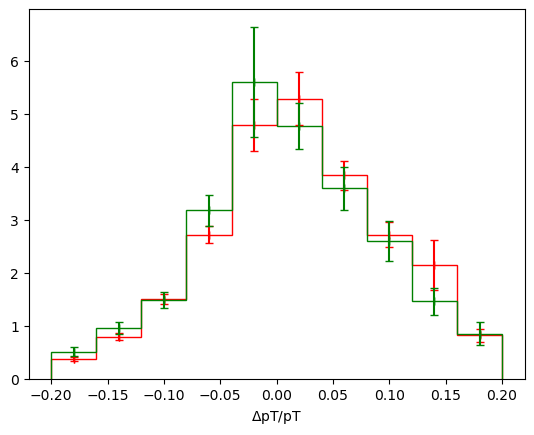

In [52]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)
    y_temp_os, yerr_temp_os, x = calc_hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    y_temp_ss, yerr_temp_ss, x = calc_hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('detector-level pT bin:', i)
    plt.hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], color='g', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_os/sum(y_temp_os), xerr=0, yerr=25*yerr_temp_os/sum(y_temp_os), color='r',ls='none',capsize=3)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_ss/sum(y_temp_ss), xerr=0, yerr=25*yerr_temp_ss/sum(y_temp_ss), color='g',ls='none',capsize=3)
    plt.xlabel('$\Delta$pT/pT')
    plt.ylim(bottom=0)
    plt.show()

In [47]:
err_on_mean_os = []
for j in range(0,4):
    df = applyCut(df_match_pts_array[j], 'b==-1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_os.append(err2)

In [50]:
err_on_mean_ss = []
for j in range(0,4):
    df = applyCut(df_match_pts_array[j], 'b==1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_ss.append(err2)

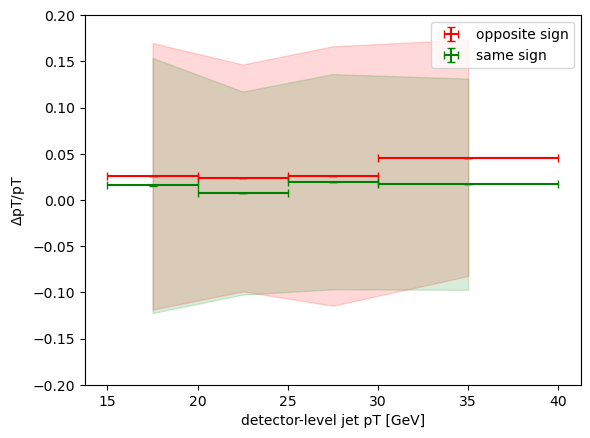

In [53]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_ss, color='g', label='same sign', ls='none', capsize=3)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_os)-np.array(sigma_dpt_pt_array_os), np.array(dpt_pt_array_os)+np.array(sigma_dpt_pt_array_os), color='r', alpha=0.15)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_ss)-np.array(sigma_dpt_pt_array_ss), np.array(dpt_pt_array_ss)+np.array(sigma_dpt_pt_array_ss), color='g', alpha=0.15)
plt.xlabel('detector-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.2,0.2)
plt.legend()

detector-level pT bin: 0


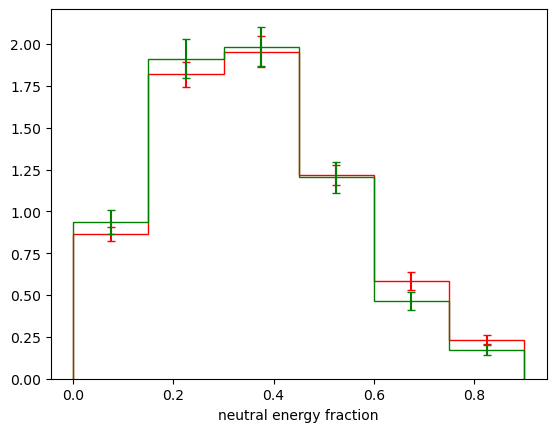

detector-level pT bin: 1


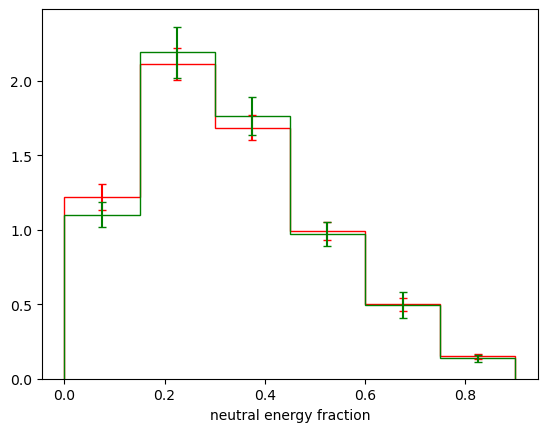

detector-level pT bin: 2


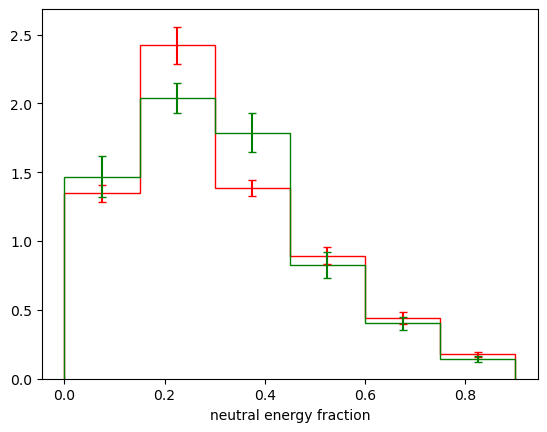

detector-level pT bin: 3


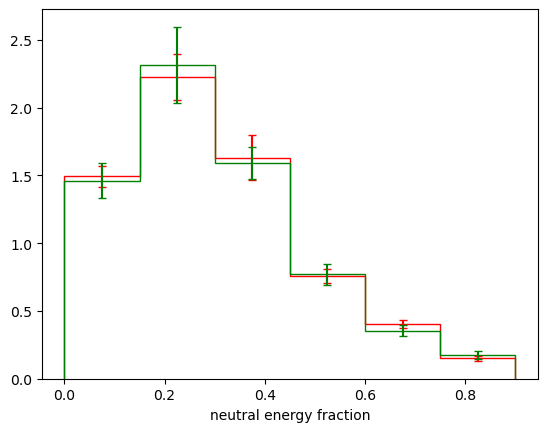

In [21]:
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs==1')
    y_temp_os, yerr_temp_os = calc_hist(df_temp_os['nefs'], weights=df_temp_os['ws'], bins=np.arange(0,1.05,0.15)[:-1], density=True)[:-1]
    y_temp_ss, yerr_temp_ss = calc_hist(df_temp_ss['nefs'], weights=df_temp_ss['ws'], bins=np.arange(0,1.05,0.15)[:-1], density=True)[:-1]
    print('detector-level pT bin:', i)
    plt.hist(df_temp_os['nefs'], weights=df_temp_os['ws'], bins=np.arange(0,1.05,0.15)[:-1], density=True, color='r', histtype='step')
    plt.hist(df_temp_ss['nefs'], weights=df_temp_ss['ws'], bins=np.arange(0,1.05,0.15)[:-1], density=True, color='g', histtype='step')
    plt.errorbar(np.arange(0.075,0.975,0.15), y_temp_os, yerr=yerr_temp_os, capsize=3, ls='none', color='r')
    plt.errorbar(np.arange(0.075,0.975,0.15), y_temp_ss, yerr=yerr_temp_ss, capsize=3, ls='none', color='g')
    plt.xlabel('neutral energy fraction')
    plt.show()

In [55]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]

truth-level pT bin: 0


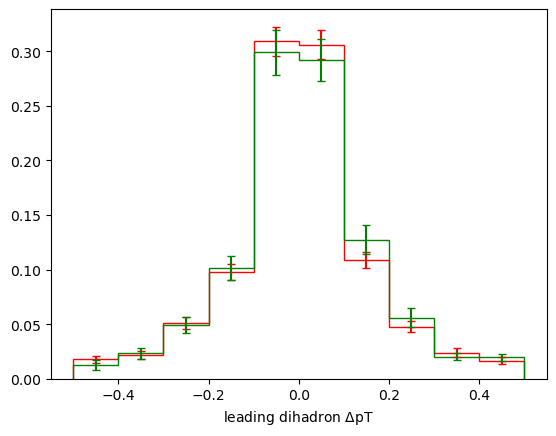

truth-level pT bin: 1


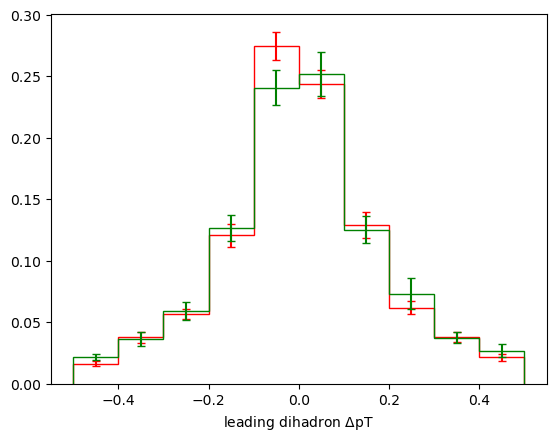

truth-level pT bin: 2


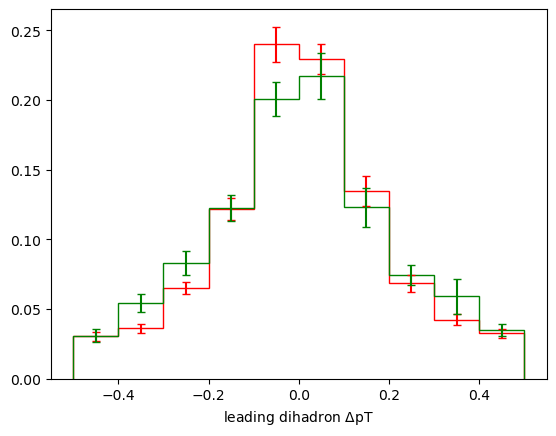

truth-level pT bin: 3


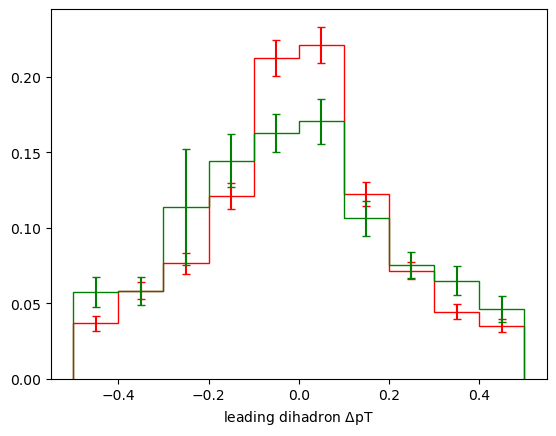

In [23]:
for i in range(0,4):
    df_temp_os = applyCut(df_match_pt_array[i], 'b==-1')
    df_temp_ss = applyCut(df_match_pt_array[i], 'b==1')
    y_temp_os, yerr_temp_os = calc_hist(df_temp_os['dpt_dihadron'], weights=df_temp_os['w'], bins=np.arange(-0.5,0.6,0.1))[:-1]
    y_temp_ss, yerr_temp_ss = calc_hist(df_temp_ss['dpt_dihadron'], weights=df_temp_ss['w'], bins=np.arange(-0.5,0.6,0.1))[:-1]
    print('truth-level pT bin:', i)
    y1 = plt.hist(df_temp_os['dpt_dihadron'], weights=df_temp_os['w']/sum(y_temp_os), bins=np.arange(-0.5,0.6,0.1), color='r', histtype='step')
    y2 = plt.hist(df_temp_ss['dpt_dihadron'], weights=df_temp_ss['w']/sum(y_temp_ss), bins=np.arange(-0.5,0.6,0.1), color='g', histtype='step')
    plt.errorbar(np.arange(-0.45,0.55,0.1), y_temp_os/sum(y_temp_os), yerr=yerr_temp_os/sum(y_temp_os), capsize=3, ls='none', color='r')
    plt.errorbar(np.arange(-0.45,0.55,0.1), y_temp_ss/sum(y_temp_ss), yerr=yerr_temp_ss/sum(y_temp_ss), capsize=3, ls='none', color='g')
    plt.xlabel('leading dihadron $\Delta$pT')
    plt.show()

truth-level pT bin: 0


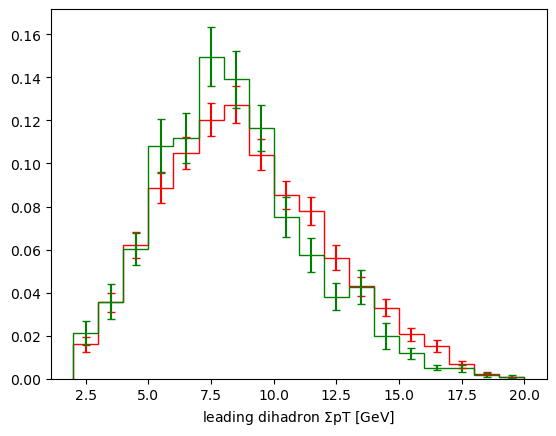

truth-level pT bin: 1


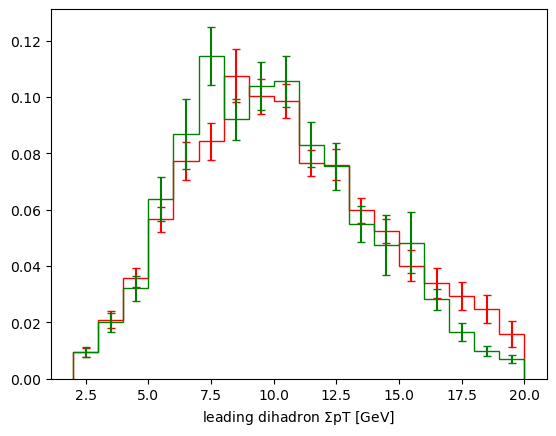

truth-level pT bin: 2


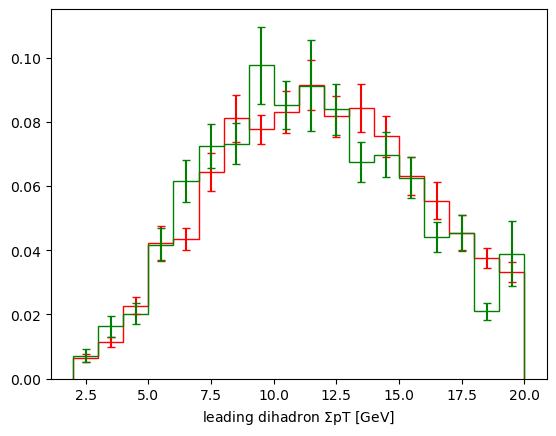

truth-level pT bin: 3


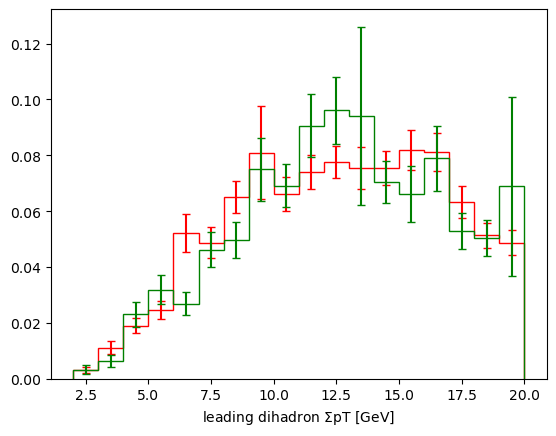

In [58]:
for i in range(0,4):
    df_temp_os = applyCut(df_match_pt_array[i], 'b==-1')
    df_temp_ss = applyCut(df_match_pt_array[i], 'b==1')
    y_temp_os, yerr_temp_os = calc_hist(df_temp_os['spt_dihadron'], weights=df_temp_os['w'], bins=np.arange(2,21))[:-1]
    y_temp_ss, yerr_temp_ss = calc_hist(df_temp_ss['spt_dihadron'], weights=df_temp_ss['w'], bins=np.arange(2,21))[:-1]
    print('truth-level pT bin:', i)
    y1 = plt.hist(df_temp_os['spt_dihadron'], weights=df_temp_os['w']/sum(y_temp_os), bins=np.arange(2,21), color='r', histtype='step')
    y2 = plt.hist(df_temp_ss['spt_dihadron'], weights=df_temp_ss['w']/sum(y_temp_ss), bins=np.arange(2,21), color='g', histtype='step')
    plt.errorbar(np.arange(2.5,20.5), y_temp_os/sum(y_temp_os), yerr=yerr_temp_os/sum(y_temp_os), capsize=3, ls='none', color='r')
    plt.errorbar(np.arange(2.5,20.5), y_temp_ss/sum(y_temp_ss), yerr=yerr_temp_ss/sum(y_temp_ss), capsize=3, ls='none', color='g')
    plt.xlabel('leading dihadron $\Sigma$pT [GeV]')
    plt.show()

truth-level pT bin: 0


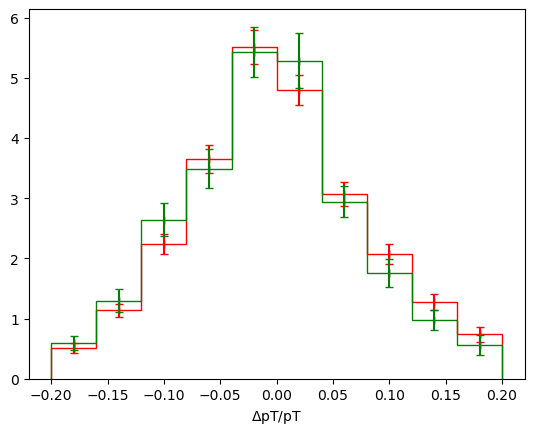

truth-level pT bin: 1


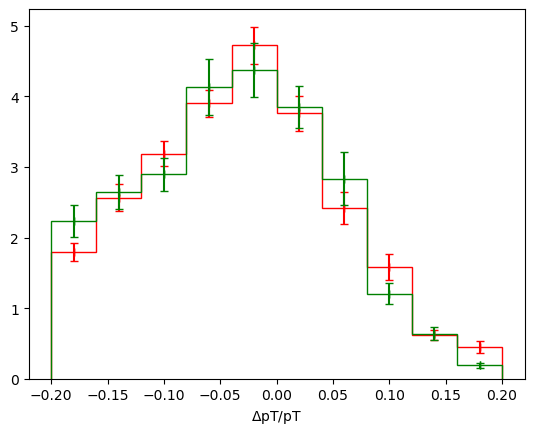

truth-level pT bin: 2


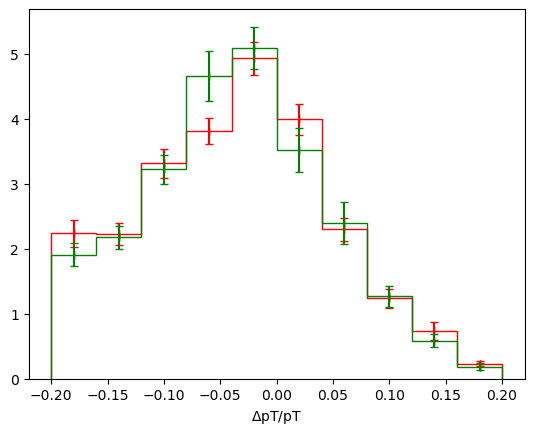

truth-level pT bin: 3


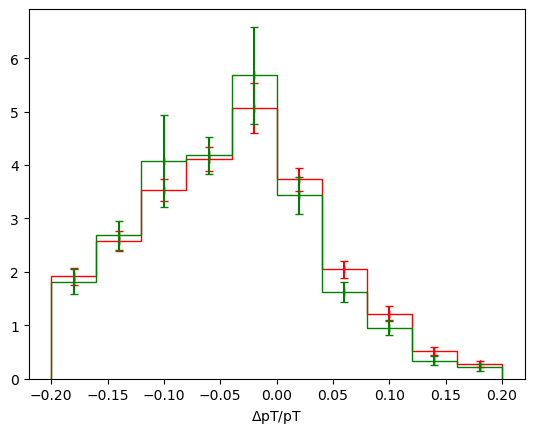

In [24]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pt_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pt_array[i], 'bs==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)
    y_temp_os, yerr_temp_os, x = calc_hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    y_temp_ss, yerr_temp_ss, x = calc_hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('truth-level pT bin:', i)
    plt.hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], color='g', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_os/sum(y_temp_os), xerr=0, yerr=25*yerr_temp_os/sum(y_temp_os), color='r',ls='none',capsize=3)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_ss/sum(y_temp_ss), xerr=0, yerr=25*yerr_temp_ss/sum(y_temp_ss), color='g',ls='none',capsize=3)
    plt.xlabel('$\Delta$pT/pT')
    plt.ylim(bottom=0)
    plt.show()

truth-level pT bin: 0


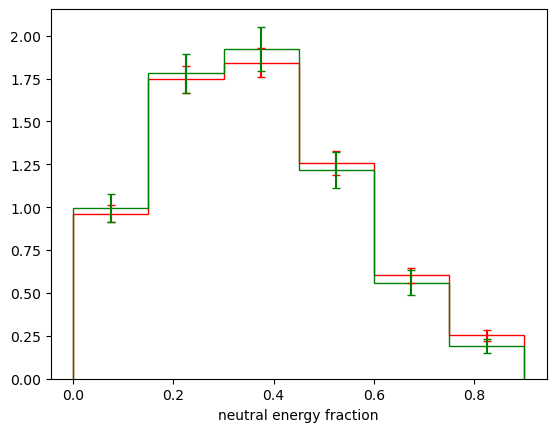

truth-level pT bin: 1


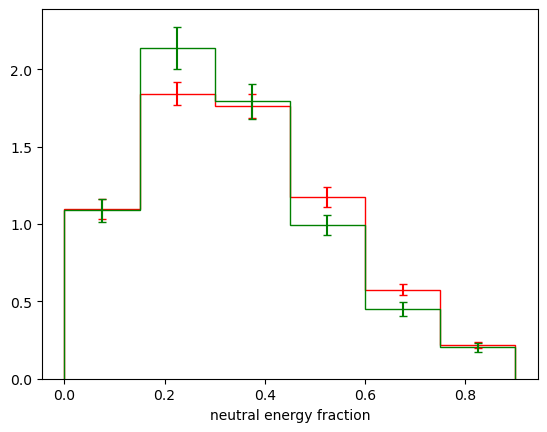

truth-level pT bin: 2


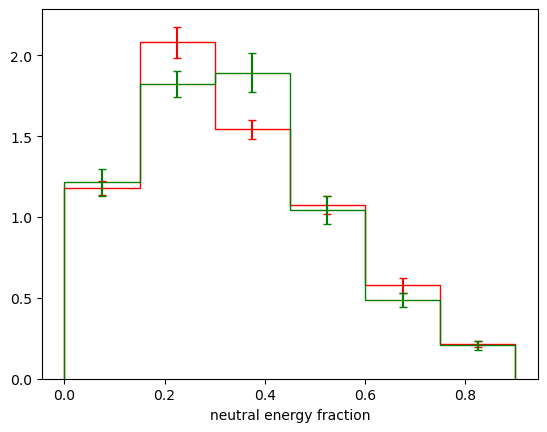

truth-level pT bin: 3


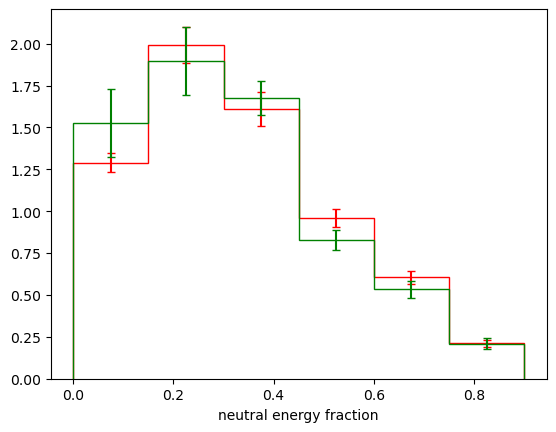

In [25]:
for i in range(0,4):
    df_temp_os = applyCut(df_match_pt_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pt_array[i], 'bs==1')
    y_temp_os, yerr_temp_os = calc_hist(df_temp_os['nefs'], weights=df_temp_os['ws'], bins=np.arange(0,1.05,0.15)[:-1], density=True)[:-1]
    y_temp_ss, yerr_temp_ss = calc_hist(df_temp_ss['nefs'], weights=df_temp_ss['ws'], bins=np.arange(0,1.05,0.15)[:-1], density=True)[:-1]
    print('truth-level pT bin:', i)
    plt.hist(df_temp_os['nefs'], weights=df_temp_os['ws'], bins=np.arange(0,1.05,0.15)[:-1], density=True, color='r', histtype='step')
    plt.hist(df_temp_ss['nefs'], weights=df_temp_ss['ws'], bins=np.arange(0,1.05,0.15)[:-1], density=True, color='g', histtype='step')
    plt.errorbar(np.arange(0.075,0.975,0.15), y_temp_os, yerr=yerr_temp_os, capsize=3, ls='none', color='r')
    plt.errorbar(np.arange(0.075,0.975,0.15), y_temp_ss, yerr=yerr_temp_ss, capsize=3, ls='none', color='g')
    plt.xlabel('neutral energy fraction')
    plt.show()

truth-level pT bin: 0


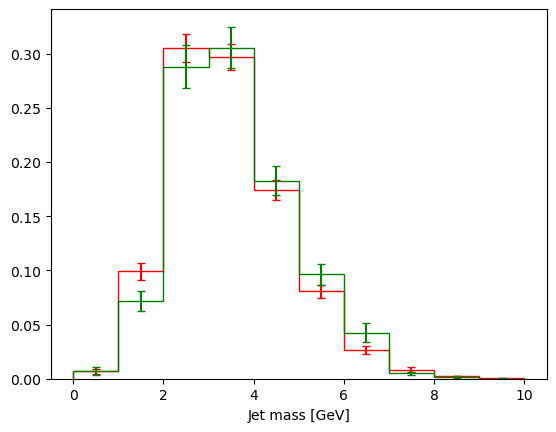

truth-level pT bin: 1


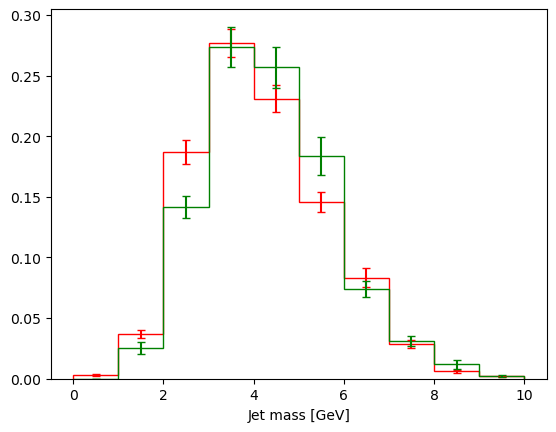

truth-level pT bin: 2


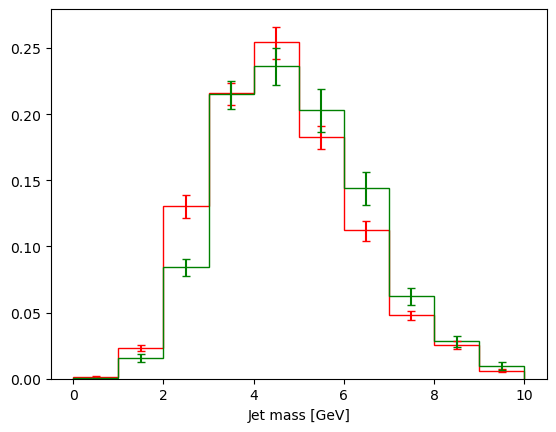

truth-level pT bin: 3


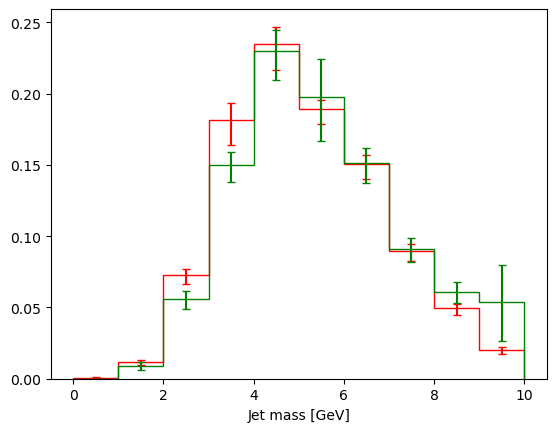

In [26]:
for i in range(0,4):
    df_temp_os = applyCut(df_match_pt_array[i], 'b==-1')
    df_temp_ss = applyCut(df_match_pt_array[i], 'b==1')
    y_temp_os, yerr_temp_os = calc_hist(df_temp_os['m'], weights=df_temp_os['w'], bins=np.arange(0,11), density=True)[:-1]
    y_temp_ss, yerr_temp_ss = calc_hist(df_temp_ss['m'], weights=df_temp_ss['w'], bins=np.arange(0,11), density=True)[:-1]
    print('truth-level pT bin:', i)
    plt.hist(df_temp_os['m'], weights=df_temp_os['w'], bins=np.arange(0,11), density=True, color='r', histtype='step')
    plt.hist(df_temp_ss['m'], weights=df_temp_ss['w'], bins=np.arange(0,11), density=True, color='g', histtype='step')
    plt.errorbar(np.arange(0.5,10.5), y_temp_os, yerr=yerr_temp_os, capsize=3, ls='none', color='r')
    plt.errorbar(np.arange(0.5,10.5), y_temp_ss, yerr=yerr_temp_ss, capsize=3, ls='none', color='g')
    plt.xlabel('Jet mass [GeV]')
    plt.show()

In [39]:
err_on_mean_os = []
for j in range(0,4):
    df = applyCut(df_match_pt_array[j], 'b==-1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_os.append(err2)

In [40]:
err_on_mean_ss = []
for j in range(0,4):
    df = applyCut(df_match_pt_array[j], 'b==1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_ss.append(err2)

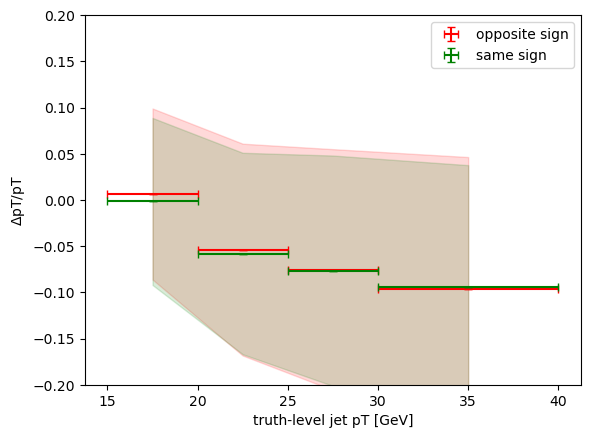

In [41]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_ss, color='g', label='same sign', ls='none', capsize=3)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_os)-np.array(sigma_dpt_pt_array_os), np.array(dpt_pt_array_os)+np.array(sigma_dpt_pt_array_os), color='r', alpha=0.15)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_ss)-np.array(sigma_dpt_pt_array_ss), np.array(dpt_pt_array_ss)+np.array(sigma_dpt_pt_array_ss), color='g', alpha=0.15)
plt.xlabel('truth-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.2,0.2)
plt.legend()

In [34]:
dpt_array_os = []
sigma_dpt_array_os = []
dpt_array_ss = []
sigma_dpt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs==1')
    dpt_os, sigma_dpt_os = weighted_avg_and_std(df_temp_os['dpt'], df_temp_os['w'])
    dpt_ss, sigma_dpt_ss = weighted_avg_and_std(df_temp_ss['dpt'], df_temp_ss['w'])
    dpt_array_os.append(dpt_os)
    sigma_dpt_array_os.append(sigma_dpt_os)
    dpt_array_ss.append(dpt_ss)
    sigma_dpt_array_ss.append(sigma_dpt_ss)

In [79]:
err_on_mean_os = []
for j in range(0,4):
    df = applyCut(df_match_pt_array[j], 'b==-1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_os.append(err2)

In [35]:
err_on_mean_ss = []
for j in range(0,4):
    df = applyCut(df_match_pt_array[j], 'b==1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_ss.append(err2)

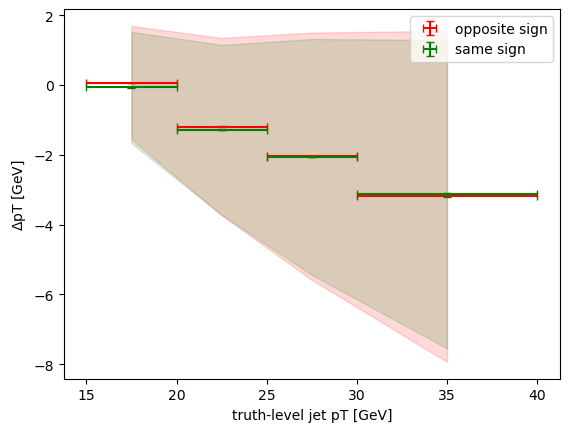

In [46]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_ss, color='g', label='same sign', ls='none', capsize=3)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_array_os)-np.array(sigma_dpt_array_os), np.array(dpt_array_os)+np.array(sigma_dpt_array_os), color='r', alpha=0.15)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_array_ss)-np.array(sigma_dpt_array_ss), np.array(dpt_array_ss)+np.array(sigma_dpt_array_ss), color='g', alpha=0.15)
plt.xlabel('truth-level jet pT [GeV]')
plt.ylabel('$\Delta$pT [GeV]')
#plt.ylim(-0.2,0.2)
plt.legend()

In [62]:
spt_dihadron_array_os = []
sigma_spt_dihadron_array_os = []
spt_dihadron_array_ss = []
sigma_spt_dihadron_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pt_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pt_array[i], 'bs==1')
    spt_dihadron_os, sigma_spt_dihadron_os = weighted_avg_and_std(df_temp_os['spt_dihadron'], df_temp_os['w'])
    spt_dihadron_ss, sigma_spt_dihadron_ss = weighted_avg_and_std(df_temp_ss['spt_dihadron'], df_temp_ss['w'])
    spt_dihadron_array_os.append(spt_dihadron_os)
    sigma_spt_dihadron_array_os.append(sigma_spt_dihadron_os)
    spt_dihadron_array_ss.append(spt_dihadron_ss)
    sigma_spt_dihadron_array_ss.append(sigma_spt_dihadron_ss)

In [60]:
err_on_mean_os = []
for j in range(0,4):
    df = applyCut(df_match_pt_array[j], 'b==-1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['spt_dihadron'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_os.append(err2)

In [61]:
err_on_mean_ss = []
for j in range(0,4):
    df = applyCut(df_match_pt_array[j], 'b==1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['spt_dihadron'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_ss.append(err2)

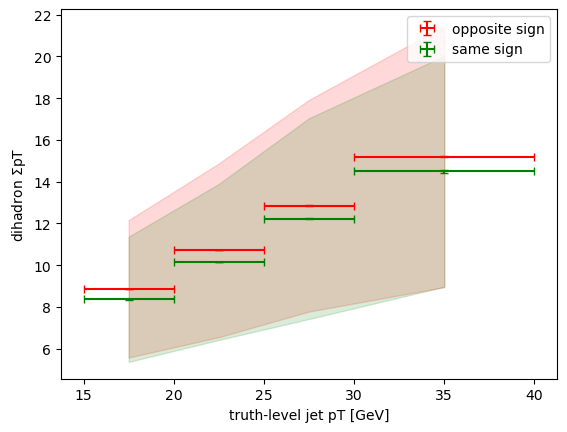

In [65]:
plt.errorbar([17.5, 22.5, 27.5, 35], spt_dihadron_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], spt_dihadron_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_ss, color='g', label='same sign', ls='none', capsize=3)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(spt_dihadron_array_os)-np.array(sigma_spt_dihadron_array_os), np.array(spt_dihadron_array_os)+np.array(sigma_spt_dihadron_array_os), color='r', alpha=0.15)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(spt_dihadron_array_ss)-np.array(sigma_spt_dihadron_array_ss), np.array(spt_dihadron_array_ss)+np.array(sigma_spt_dihadron_array_ss), color='g', alpha=0.15)
plt.xlabel('truth-level jet pT [GeV]')
plt.ylabel('dihadron $\Sigma$pT')
#plt.ylim(-0.2,0.2)
plt.legend()

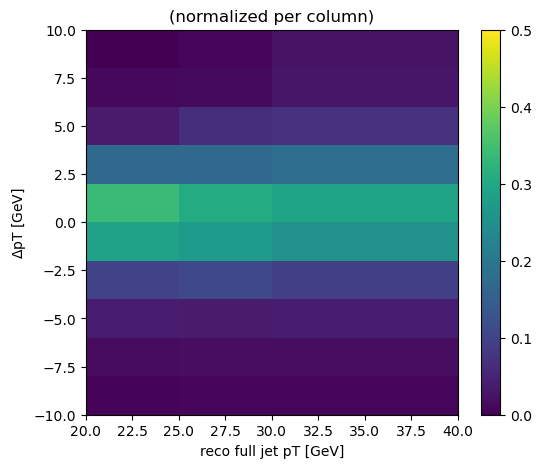

In [26]:
plt.figure(figsize=(6,5))
h,x,y = np.histogram2d(df_match['pts'], df_match['dpt'], weights=df_match['w'], bins=[np.arange(15,45,5),np.arange(-10,12,2)], density=True)
w = w_norm_per_xbin(h,[15,20,25,30,40],[-10,-8,-6,-4,-2,0,2,4,6,8,10])
plt.pcolormesh([15,20,25,30,40],[-10,-8,-6,-4,-2,0,2,4,6,8,10], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('$\Delta$pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(20,40)
plt.ylim(-10,10)
plt.clim(0,0.5)

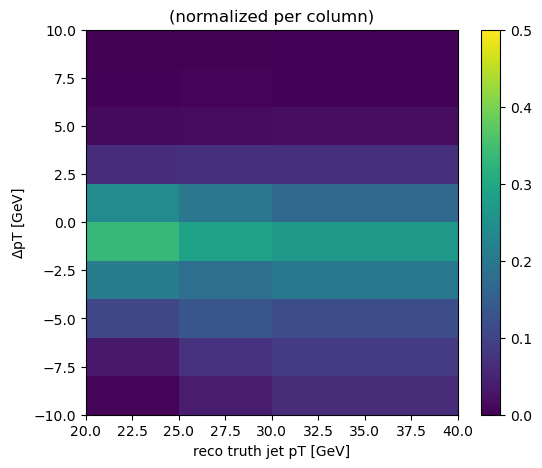

In [28]:
plt.figure(figsize=(6,5))
h,x,y = np.histogram2d(df_match['pt'], df_match['dpt'], weights=df_match['w'], bins=[np.arange(15,45,5),np.arange(-10,12,2)], density=True)
w = w_norm_per_xbin(h,[15,20,25,30,40],[-10,-8,-6,-4,-2,0,2,4,6,8,10])
plt.pcolormesh([15,20,25,30,40],[-10,-8,-6,-4,-2,0,2,4,6,8,10], np.transpose(w))
plt.xlabel('reco truth jet pT [GeV]')
plt.ylabel('$\Delta$pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(20,40)
plt.ylim(-10,10)
plt.clim(0,0.5)

In [29]:
h,x,y = np.histogram2d(df_match['pt'],df_match['pts'], bins=([15,20,25,30,40]), weights=df_match['w'], density=True)

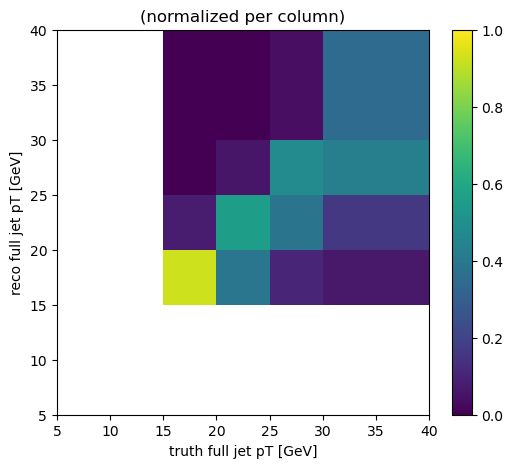

In [30]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[15,20,25,30,40],[15,20,25,30,40])
plt.pcolormesh([15,20,25,30,40],[15,20,25,30,40], np.transpose(w))
plt.xlabel('truth full jet pT [GeV]')
plt.ylabel('reco full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

In [13]:
h,x,y = np.histogram2d(df_match['pts'],df_match['pt'], bins=([5,10,15,20,25,30,40]), weights=df_match['w'], density=True)

/tmp/ipykernel_17182/2021765472.py:5: RuntimeWarning: invalid value encountered in scalar divide
  w[i][j] = h[i][j]/sum(h[i]) + 10**-50


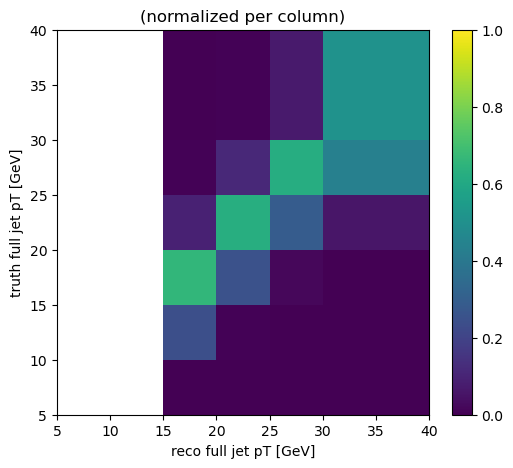

In [14]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('truth full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

separate response matrices for opposite and same sign pairs 

In [56]:
h,x,y = np.histogram2d(df_match[df_match.bs==-1]['pt'],df_match[df_match.bs==-1]['pts'], bins=([15,20,25,30,40]), weights=df_match[df_match.bs==-1]['w'], density=True)

(15.0, 40.0)

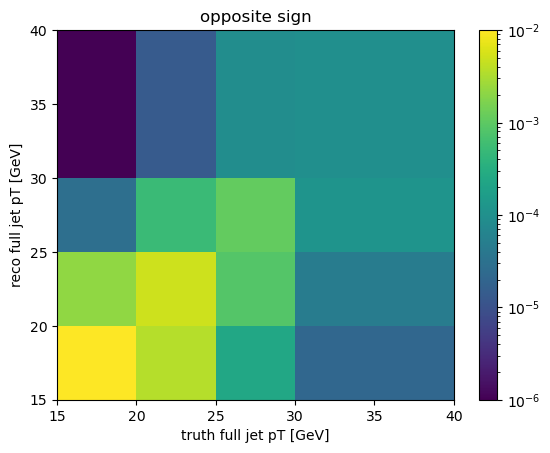

In [59]:
plt.hist2d(df_match[df_match.bs==-1]['pt'],df_match[df_match.bs==-1]['pts'], bins=([15,20,25,30,40]), norm=matplotlib.colors.LogNorm(), weights=df_match[df_match.bs==-1]['w'], density=True)
plt.xlabel('truth full jet pT [GeV]')
plt.ylabel('reco full jet pT [GeV]')
plt.title('opposite sign')
plt.colorbar()
plt.clim(1e-6,1e-2)
plt.xlim(15,40)
plt.ylim(15,40)

(15.0, 40.0)

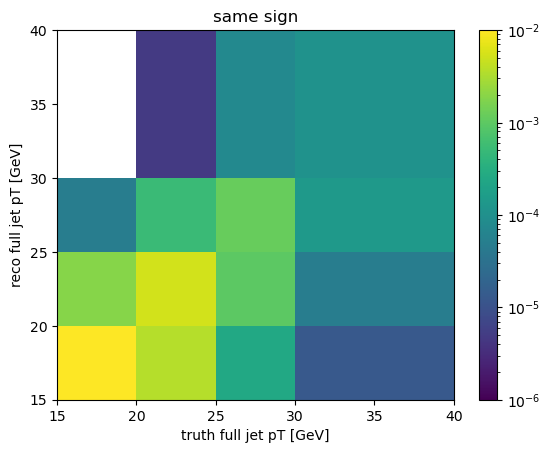

In [60]:
plt.hist2d(df_match[df_match.bs==1]['pt'],df_match[df_match.bs==1]['pts'], bins=([15,20,25,30,40]), norm=matplotlib.colors.LogNorm(), weights=df_match[df_match.bs==1]['w'], density=True)
plt.xlabel('truth full jet pT [GeV]')
plt.ylabel('reco full jet pT [GeV]')
plt.title('same sign')
plt.colorbar()
plt.clim(1e-6,1e-2)
plt.xlim(15,40)
plt.ylim(15,40)

In [76]:
h,x,y = np.histogram2d(df_match[df_match.bs==-1]['pt'],df_match[df_match.bs==-1]['pts'], bins=([15,20,25,30,40]), weights=df_match[df_match.bs==-1]['w'], density=True)

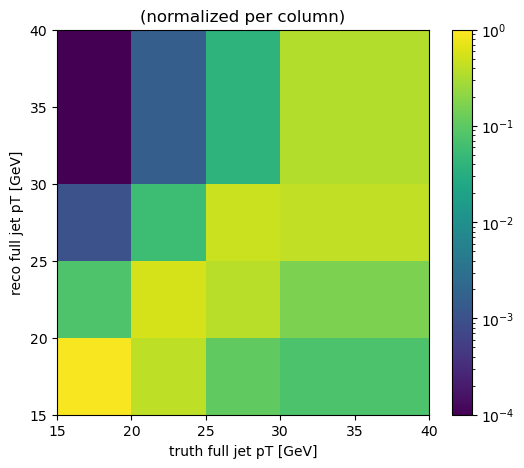

In [78]:
import matplotlib.colors as colors
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[15,20,25,30,40],[15,20,25,30,40])
plt.pcolormesh([15,20,25,30,40],[15,20,25,30,40], np.transpose(w), norm=colors.LogNorm())
plt.xlabel('truth full jet pT [GeV]')
plt.ylabel('reco full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(15,40)
plt.ylim(15,40)
plt.clim(1e-4,1)

In [79]:
h,x,y = np.histogram2d(df_match[df_match.bs==1]['pt'],df_match[df_match.bs==1]['pts'], bins=([15,20,25,30,40]), weights=df_match[df_match.bs==1]['w'], density=True)

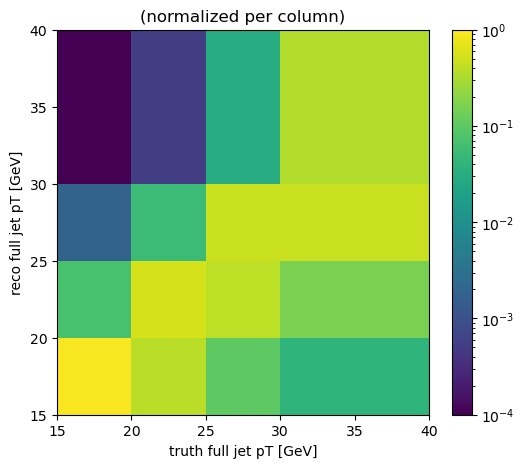

In [80]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[15,20,25,30,40],[15,20,25,30,40])
plt.pcolormesh([15,20,25,30,40],[15,20,25,30,40], np.transpose(w), norm=colors.LogNorm())
plt.xlabel('truth full jet pT [GeV]')
plt.ylabel('reco full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(15,40)
plt.ylim(15,40)
plt.clim(1e-4,1)

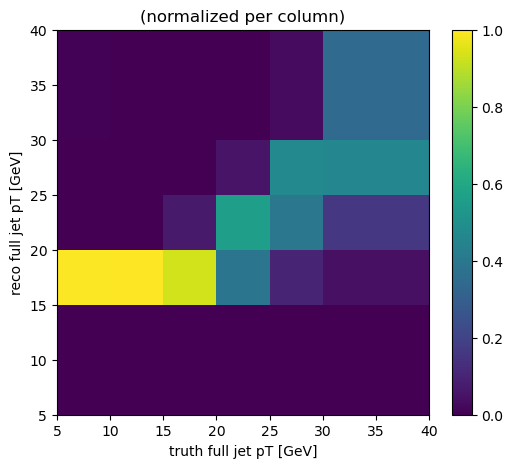

In [36]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('truth full jet pT [GeV]')
plt.ylabel('reco full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

In [28]:
h,x,y = np.histogram2d(df_match[df_match.bs==-1]['pts'],df_match[df_match.bs==-1]['pt'], bins=([5,10,15,20,25,30,40]), weights=df_match[df_match.bs==-1]['w'], density=True)

/tmp/ipykernel_17182/2021765472.py:5: RuntimeWarning: invalid value encountered in scalar divide
  w[i][j] = h[i][j]/sum(h[i]) + 10**-50


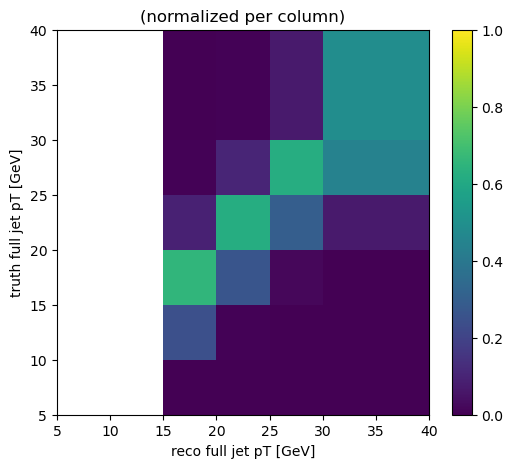

In [29]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('truth full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

In [30]:
h,x,y = np.histogram2d(df_match[df_match.bs==+1]['pts'],df_match[df_match.bs==+1]['pt'], bins=([5,10,15,20,25,30,40]), weights=df_match[df_match.bs==+1]['w'], density=True)

/tmp/ipykernel_17182/2021765472.py:5: RuntimeWarning: invalid value encountered in scalar divide
  w[i][j] = h[i][j]/sum(h[i]) + 10**-50


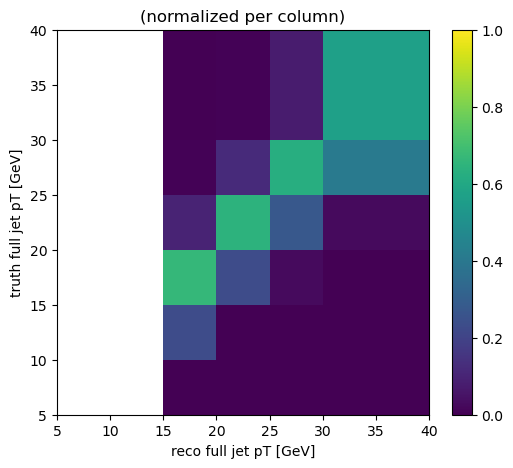

In [31]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('truth full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

HERWIG7+fast sim

In [70]:
df = pd.read_csv('herwig.csv')

In [71]:
df_match = applyCut(df, 'pt>5 and b_ch!=-9 and distance1 < 0.02 and distance2 < 0.02')

In [72]:
df_match.eval('dpt_pt = (pts-pt)/pt', inplace=True)

In [80]:
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

In [81]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs_ch==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs_ch==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)    

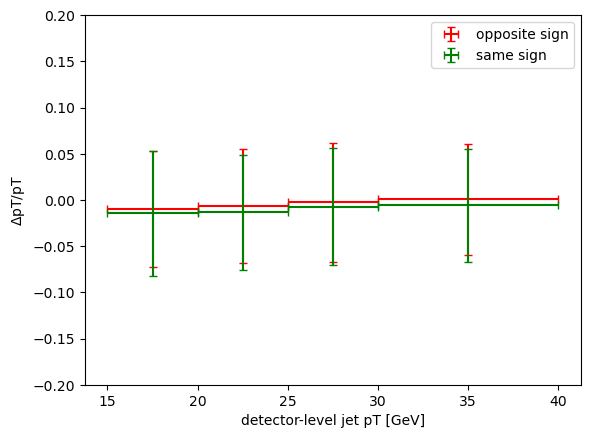

In [82]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_ss, color='g', label='same sign', ls='none', capsize=3)
plt.xlabel('detector-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.2,0.2)
plt.legend()

In [76]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]

In [77]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pt_array[i], 'bs_ch==-1')
    df_temp_ss = applyCut(df_match_pt_array[i], 'bs_ch==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)    

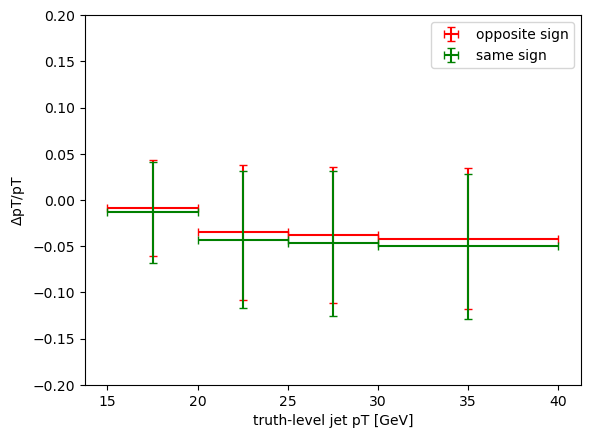

In [79]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_ss, color='g', label='same sign', ls='none', capsize=3)
plt.xlabel('truth-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.2,0.2)
plt.legend()

In [17]:
h,x,y = np.histogram2d(df_match['pt'],df_match['pts'], bins=([5,10,15,20,25,30,40]), weights=df_match['w'], density=True)

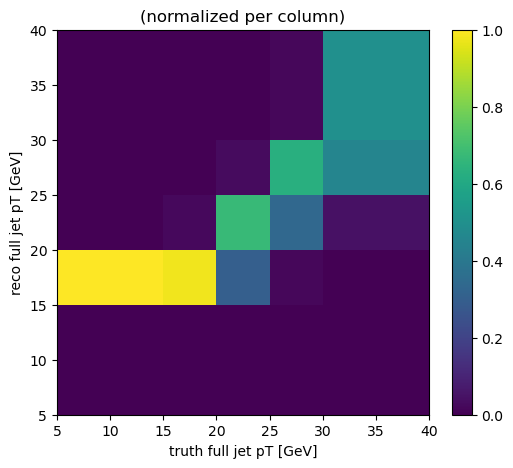

In [18]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('truth full jet pT [GeV]')
plt.ylabel('reco full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

In [19]:
h,x,y = np.histogram2d(df_match['pts'],df_match['pt'], bins=([5,10,15,20,25,30,40]), weights=df_match['w'], density=True)

/tmp/ipykernel_17182/2021765472.py:5: RuntimeWarning: invalid value encountered in scalar divide
  w[i][j] = h[i][j]/sum(h[i]) + 10**-50


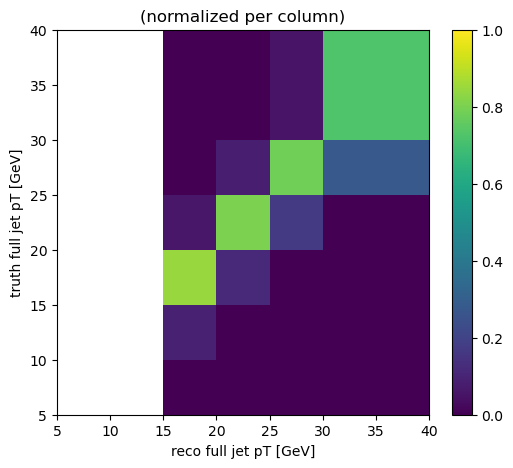

In [20]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('truth full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

separate response matrices for opposite and same sign pairs 

In [21]:
h,x,y = np.histogram2d(df_match[df_match.bs_ch==-1]['pts'],df_match[df_match.bs_ch==-1]['pt'], bins=([5,10,15,20,25,30,40]), weights=df_match[df_match.bs_ch==-1]['w'], density=True)

/tmp/ipykernel_17182/2021765472.py:5: RuntimeWarning: invalid value encountered in scalar divide
  w[i][j] = h[i][j]/sum(h[i]) + 10**-50


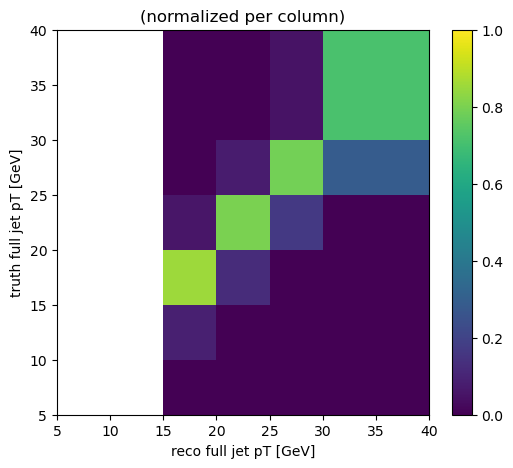

In [22]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('truth full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

In [23]:
h,x,y = np.histogram2d(df_match[df_match.bs_ch==+1]['pts'],df_match[df_match.bs_ch==+1]['pt'], bins=([5,10,15,20,25,30,40]), weights=df_match[df_match.bs_ch==+1]['w'], density=True)

/tmp/ipykernel_17182/2021765472.py:5: RuntimeWarning: invalid value encountered in scalar divide
  w[i][j] = h[i][j]/sum(h[i]) + 10**-50


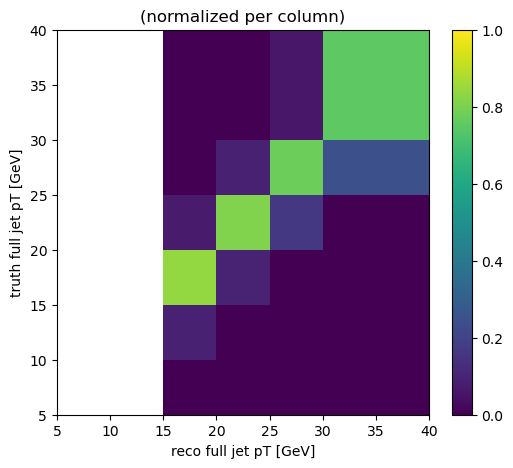

In [24]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('truth full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

In [122]:
rc_1 = getRc(applyCut(df_match,'25<pt<30'))
rc_err_1 = getRcErr(applyCut(df_match,'25<pt<30'))

In [123]:
rc_2 = getRc(applyCut(df_match,'30<pt<40'))
rc_err_2 = getRcErr(applyCut(df_match,'30<pt<40'))

In [124]:
rcs_00 = getRcs(applyCut(df_match,'15<pt<20'))
rcs_err_00 = getRcsErr(applyCut(df_match,'15<pt<20'))

In [125]:
rcs_0 = getRcs(applyCut(df_match,'20<pt<25'))
rcs_err_0 = getRcsErr(applyCut(df_match,'20<pt<25'))

In [126]:
rcs_1 = getRcs(applyCut(df_match,'25<pt<30'))
rcs_err_1 = getRcsErr(applyCut(df_match,'25<pt<30'))

In [127]:
rcs_2 = getRcs(applyCut(df_match,'30<pt<40'))
rcs_err_2 = getRcsErr(applyCut(df_match,'30<pt<40'))

Text(0.5, 1.0, 'Matching cut: truth pT > 15 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

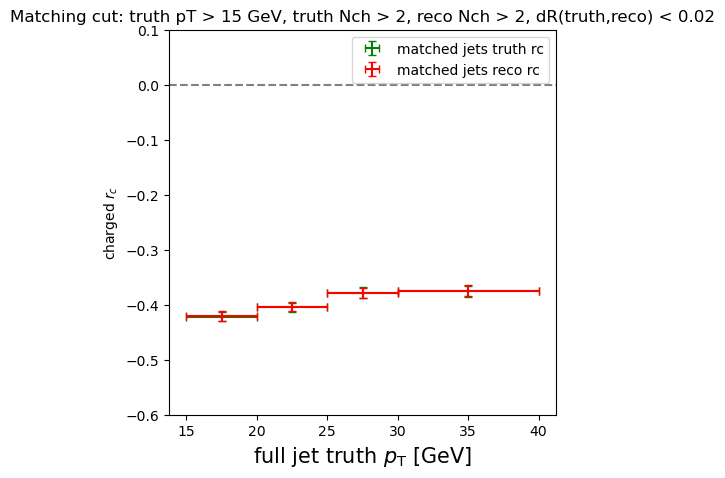

In [128]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00, rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00, rc_err_0, rc_err_1, rc_err_2], capsize=3, color='g', ls='none', label='matched jets truth rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00, rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='r', ls='none', label='matched jets reco rc')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,0.1)
plt.legend()
plt.title('Matching cut: truth pT > 15 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [26]:
w_array = np.unique(df_allreco['w'])

In [35]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)] ]

In [36]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])

In [23]:
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

In [27]:
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

In [29]:
df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)] ]

In [30]:
rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [55]:
df_fake1_pts_array = [ df_fake1[(df_fake1.pts>15) & (df_fake1.pts<20)],\
                       df_fake1[(df_fake1.pts>20) & (df_fake1.pts<25)],\
                       df_fake1[(df_fake1.pts>25) & (df_fake1.pts<30)],\
                       df_fake1[(df_fake1.pts>30) & (df_fake1.pts<40)] ]

In [56]:
rc_fake1_bs_vs_pts_array = []
rc_err_fake1_bs_vs_pts_array = []
for i in range(0, len(df_fake1_pts_array)):
    rc_fake1_bs_vs_pts_array.append(getRcAndErr(df_fake1_pts_array[i], 'bs')[0])
    rc_err_fake1_bs_vs_pts_array.append(getRcAndErr(df_fake1_pts_array[i], 'bs')[1])

In [65]:
df_fake2_pts_array = [ df_fake2[(df_fake2.pts>15) & (df_fake2.pts<20)],\
                       df_fake2[(df_fake2.pts>20) & (df_fake2.pts<25)],\
                       df_fake2[(df_fake2.pts>25) & (df_fake2.pts<30)],\
                       df_fake2[(df_fake2.pts>30) & (df_fake2.pts<40)] ]

In [66]:
rc_fake2_bs_vs_pts_array = []
rc_err_fake2_bs_vs_pts_array = []
for i in range(0, len(df_fake2_pts_array)):
    rc_fake2_bs_vs_pts_array.append(getRcAndErr(df_fake2_pts_array[i], 'bs')[0])
    rc_err_fake2_bs_vs_pts_array.append(getRcAndErr(df_fake2_pts_array[i], 'bs')[1])

In [67]:
df_fake3_pts_array = [ df_fake3[(df_fake3.pts>15) & (df_fake3.pts<20)],\
                       df_fake3[(df_fake3.pts>20) & (df_fake3.pts<25)],\
                       df_fake3[(df_fake3.pts>25) & (df_fake3.pts<30)],\
                       df_fake3[(df_fake3.pts>30) & (df_fake3.pts<40)] ]

In [70]:
rc_fake3_bs_vs_pts_array = []
rc_err_fake3_bs_vs_pts_array = []
for i in range(0, len(df_fake3_pts_array)):
    rc_fake3_bs_vs_pts_array.append(getRcAndErr(df_fake3_pts_array[i], 'bs')[0])
    rc_err_fake3_bs_vs_pts_array.append(getRcAndErr(df_fake3_pts_array[i], 'bs')[1])

Text(0.5, 1.0, '')

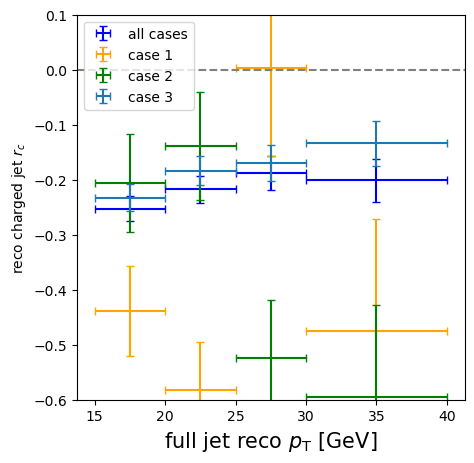

In [75]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='all cases')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_fake1_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fake1_bs_vs_pts_array, capsize=3, color='orange', ls='none', label='case 1')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_fake2_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fake2_bs_vs_pts_array, capsize=3, color='g', ls='none', label='case 2')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_fake3_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fake3_bs_vs_pts_array, capsize=3, ls='none', label='case 3')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
plt.title('')

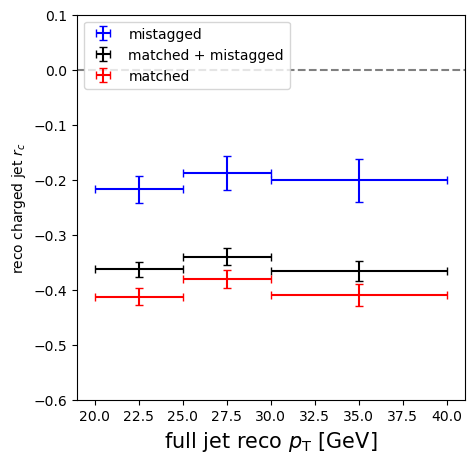

In [78]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_allfake_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array[1:], capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([22.5, 27.5, 35], rc_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
#plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

Text(0.5, 1.0, 'Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

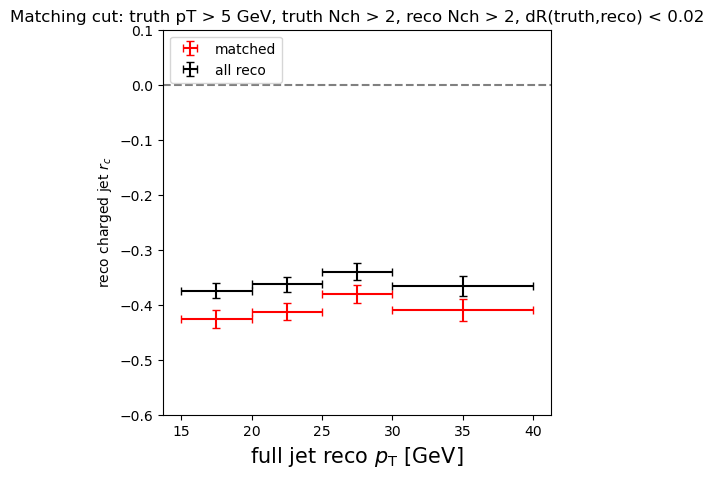

In [41]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='all reco')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [47]:
np.array(rc_allreco_bs_vs_pts_array)-np.array(rc_match_bs_vs_pts_array)

array([0.05049298, 0.04976062, 0.04134469, 0.04356509])

Text(0.5, 1.0, 'Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

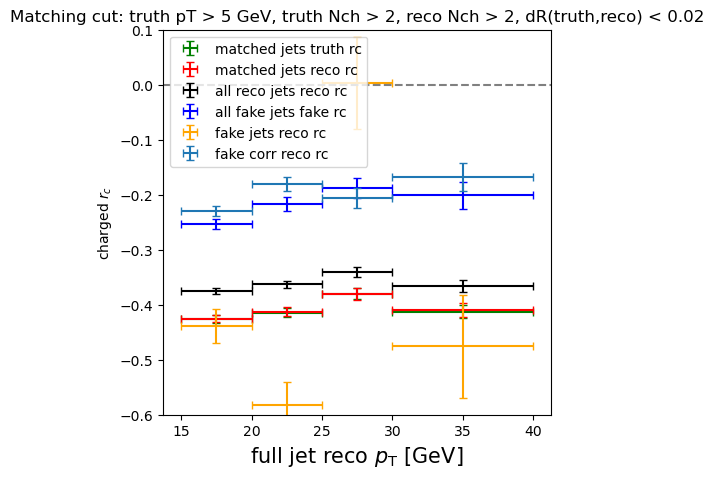

In [381]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00, rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00, rc_err_0, rc_err_1, rc_err_2], capsize=3, color='g', ls='none', label='matched jets truth rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00, rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='r', ls='none', label='matched jets reco rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00_allreco, rcs_0_allreco, rcs_1_allreco, rcs_2_allreco], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00_allreco, rcs_err_0_allreco, rcs_err_1_allreco, rcs_err_2_allreco], capsize=3, color='k', ls='none', label='all reco jets reco rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00_allfake, rcs_0_allfake, rcs_1_allfake, rcs_2_allfake], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00_allfake, rcs_err_0_allfake, rcs_err_1_allfake, rcs_err_2_allfake], capsize=3, color='b', ls='none', label='all fake jets fake rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00_fakejet, rcs_0_fakejet, rcs_1_fakejet, rcs_2_fakejet], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00_fakejet, rcs_err_0_fakejet, rcs_err_1_fakejet, rcs_err_2_fakejet], capsize=3, color='orange', ls='none', label='fake jets reco rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00_fakecorr, rcs_0_fakecorr, rcs_1_fakecorr, rcs_2_fakecorr], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00_fakecorr, rcs_err_0_fakecorr, rcs_err_1_fakecorr, rcs_err_2_fakecorr], capsize=3, ls='none', label='fake corr reco rc')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

Investigate high weight jets

In [384]:
print(df_fakejet_20[(df_fakejet_20.bs==-1) & (df_fakejet_20.w>4e-9)].shape[0])
print(df_fakejet_20[(df_fakejet_20.bs==1) & (df_fakejet_20.w>4e-9)].shape[0])

2
0


In [385]:
print(df_fakejet_25[(df_fakejet_25.bs==-1) & (df_fakejet_25.w>5e-10)].shape[0])
print(df_fakejet_25[(df_fakejet_25.bs==1) & (df_fakejet_25.w>5e-10)].shape[0])

9
2


In [386]:
print(df_fakejet_30[(df_fakejet_30.bs==-1) & (df_fakejet_30.w>5e-10)].shape[0])
print(df_fakejet_30[(df_fakejet_30.bs==1) & (df_fakejet_30.w>5e-10)].shape[0])

2
1


In [387]:
print(df_notfakejet_20[df_notfakejet_20.w>4e-9].shape[0])
print(df_notfakejet_25[df_notfakejet_25.w>5e-10].shape[0])
print(df_notfakejet_30[df_notfakejet_30.w>5e-10].shape[0])

26
609
75


In [388]:
print(df_fakejet_20.shape[0])
print(df_notfakejet_20.shape[0])

379
19584


In [389]:
np.unique(df_allreco['w'])

array([2.15385002e-11, 1.27623315e-10, 5.68292191e-10, 3.41630102e-09,
       1.43789896e-08, 1.94674001e-08, 8.28750188e-08])

In [202]:
print(max(df_fakejet_25['w']))
print(max(df_notfakejet_25['w']))

3.416301019854018e-09
3.416301019854018e-09


Fake subtraction

In [48]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [49]:
df_match_20 = applyCut(df_match, '20 < pts < 25')
df_allreco_20 = applyCut(df_allreco, '20 < pts < 25')
df_fake_20 = applyCut(df_allfake, '20 < pts < 25')
df_fakejet_20 = applyCut(df_fakejet, '20 < pts < 25')
df_fakecorr_20 = applyCut(df_fakecorr, '20 < pts < 25')
df_notfakejet_20 = applyCut(df_notfakejet, '20 < pts < 25')

In [50]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_20['w'], density=True)
y_allreco_rec,yerr_allreco_rec,x = calc_hist(df_allreco_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_20['w'], density=True)
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_20['w'], density=True)
y_fakejet_rec,yerr_fakejet_rec,x = calc_hist(df_fakejet_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakejet_20['w'], density=True)
y_notfakejet_rec,yerr_notfakejet_rec,x = calc_hist(df_notfakejet_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_notfakejet_20['w'], density=True)
y_fakecorr_rec,yerr_fakecorr_rec,x = calc_hist(df_fakecorr_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakecorr_20['w'], density=True)

(0.0, 0.9950139788690435)

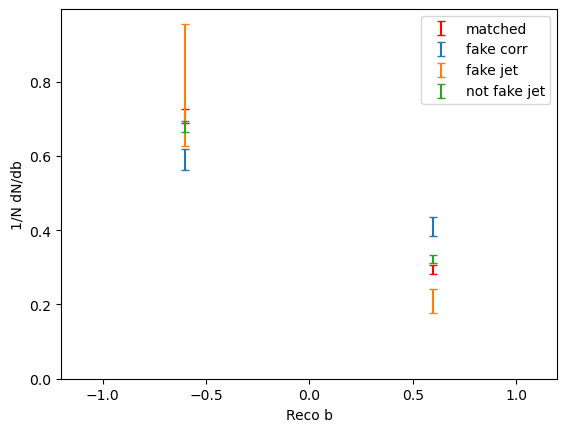

In [46]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
#plt.errorbar(x, y_allreco_rec/sum(y_allreco_rec), yerr=yerr_allreco_rec/sum(y_allreco_rec), capsize=3, color='k', label='all reco', ls='none')
plt.errorbar(x, y_match_rec/sum(y_match_rec), yerr=yerr_match_rec/sum(y_match_rec), capsize=3, color='r', label='matched', ls='none')
#plt.errorbar(x, y_fake_rec/sum(y_fake_rec), yerr=yerr_fake_rec/sum(y_fake_rec), capsize=3, color='b', label='all fake', ls='none')
plt.errorbar(x, y_fakecorr_rec/sum(y_fakecorr_rec), yerr=yerr_fakecorr_rec/sum(y_fakecorr_rec), capsize=3, label='fake corr', ls='none')
plt.errorbar(x, y_fakejet_rec/sum(y_fakejet_rec), yerr=yerr_fakejet_rec/sum(y_fakejet_rec), capsize=3, label='fake jet', ls='none')
plt.errorbar(x, y_notfakejet_rec/sum(y_notfakejet_rec), yerr=yerr_notfakejet_rec/sum(y_notfakejet_rec), capsize=3, label='not fake jet', ls='none')
plt.legend()
plt.xlabel('Reco '+ob)
plt.ylabel('1/N dN/d'+ob)
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)

In [45]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.60864417 0.39135583]
[0.02912147 0.02331168]


In [51]:
print(y_match_rec/sum(y_match_rec))
print(yerr_match_rec/sum(y_match_rec))

[0.70636007 0.29363993]
[0.0189809  0.01136867]


In [47]:
print(y_fakejet_rec/sum(y_fakejet_rec))
print(yerr_fakejet_rec/sum(y_fakejet_rec))

[0.79143631 0.20856369]
[0.16456544 0.03280639]


In [48]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.60864417 0.39135583]
[0.02912147 0.02331168]


In [49]:
(y_allreco_rec/sum(y_allreco_rec))/(y_match_rec/sum(y_match_rec))
print(y_fake_rec/sum(y_fake_rec))
print(y_fakecorr_rec/sum(y_fakecorr_rec))

[0.60864417 0.39135583]
[0.58991216 0.41008784]


In [50]:
df_match_25 = applyCut(df_match, '25 < pts < 30')
df_allreco_25 = applyCut(df_allreco, '25 < pts < 30')
df_fake_25 = applyCut(df_allfake, '25 < pts < 30')
df_fakejet_25 = applyCut(df_fakejet, '25 < pts < 30')
df_fakecorr_25 = applyCut(df_fakecorr, '25 < pts < 30')
df_notfakejet_25 = applyCut(df_notfakejet, '25 < pts < 30')

In [51]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_25['w'])
y_allreco_rec,yerr_allreco_rec,x = calc_hist(df_allreco_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_25['w'])
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_25['w'])
y_fakejet_rec,yerr_fakejet_rec,x = calc_hist(df_fakejet_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakejet_25['w'])
y_fakecorr_rec,yerr_fakecorr_rec,x = calc_hist(df_fakecorr_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakecorr_25['w'])
y_notfakejet_rec,yerr_notfakejet_rec,x = calc_hist(df_notfakejet_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_notfakejet_25['w'])

(0.0, 0.7345951617385893)

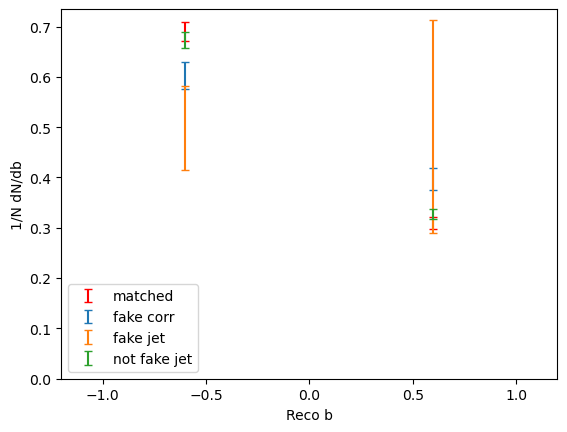

In [52]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
#plt.errorbar(x, y_allreco_rec/sum(y_allreco_rec), yerr=yerr_allreco_rec/sum(y_allreco_rec), capsize=3, color='k', label='all reco', ls='none')
plt.errorbar(x, y_match_rec/sum(y_match_rec), yerr=yerr_match_rec/sum(y_match_rec), capsize=3, color='r', label='matched', ls='none')
#plt.errorbar(x, y_fake_rec/sum(y_fake_rec), yerr=yerr_fake_rec/sum(y_fake_rec), capsize=3, color='b', label='all fake', ls='none')
plt.errorbar(x, y_fakecorr_rec/sum(y_fakecorr_rec), yerr=yerr_fakecorr_rec/sum(y_fakecorr_rec), capsize=3, label='fake corr', ls='none')
plt.errorbar(x, y_fakejet_rec/sum(y_fakejet_rec), yerr=yerr_fakejet_rec/sum(y_fakejet_rec), capsize=3, label='fake jet', ls='none')
plt.errorbar(x, y_notfakejet_rec/sum(y_notfakejet_rec), yerr=yerr_notfakejet_rec/sum(y_notfakejet_rec), capsize=3, label='not fake jet', ls='none')
plt.legend()
plt.xlabel('Reco '+ob)
plt.ylabel('1/N dN/d'+ob)
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)

In [53]:
print(y_fakejet_rec/sum(y_fakejet_rec))
print(yerr_fakejet_rec/sum(y_fakejet_rec))

[0.49836301 0.50163699]
[0.08264014 0.21178016]


In [54]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.59417459 0.40582541]
[0.02493272 0.02715528]


In [55]:
(y_allreco_rec/sum(y_allreco_rec))/(y_match_rec/sum(y_match_rec))
print(y_fake_rec/sum(y_fake_rec))
print(y_fakejet_rec/sum(y_fakejet_rec))
print(y_fakecorr_rec/sum(y_fakecorr_rec))

[0.59417459 0.40582541]
[0.49836301 0.50163699]
[0.60287497 0.39712503]


In [56]:
df_match_30 = applyCut(df_match, '30 < pts < 40')
df_allreco_30 = applyCut(df_allreco, '30 < pts < 40')
df_fake_30 = applyCut(df_allfake, '30 < pts < 40')
df_fakejet_30 = applyCut(df_fakejet, '30 < pts < 40')
df_fakecorr_30 = applyCut(df_fakecorr, '30 < pts < 40')
df_notfakejet_30 = applyCut(df_notfakejet, '30 < pts < 40')

In [32]:
print(max(df_fakejet_30['w']))
print(max(df_notfakejet_30['w']))

3.416301019854018e-09
3.416301019854018e-09


In [57]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_30['w'])
y_allreco_rec,yerr_allreco_rec,x = calc_hist(df_allreco_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_30['w'])
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_30['w'])
y_fakejet_rec,yerr_fakejet_rec,x = calc_hist(df_fakejet_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakejet_30['w'])
y_fakecorr_rec,yerr_fakecorr_rec,x = calc_hist(df_fakecorr_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakecorr_30['w'])

(0.0, 1.159906207394859)

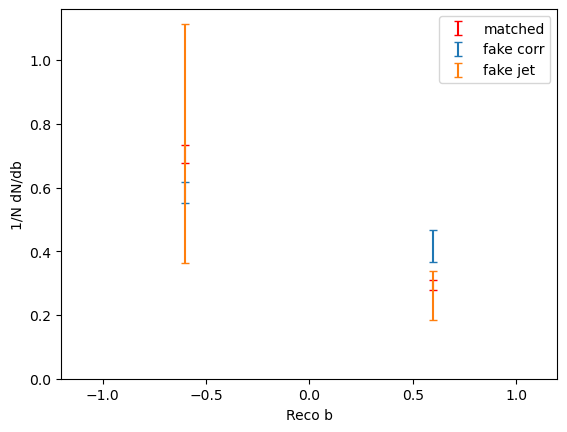

In [58]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
#plt.errorbar(x, y_allreco_rec/sum(y_allreco_rec), yerr=yerr_allreco_rec/sum(y_allreco_rec), capsize=3, color='k', label='all reco', ls='none')
plt.errorbar(x, y_match_rec/sum(y_match_rec), yerr=yerr_match_rec/sum(y_match_rec), capsize=3, color='r', label='matched', ls='none')
#plt.errorbar(x, y_fake_rec/sum(y_fake_rec), yerr=yerr_fake_rec/sum(y_fake_rec), capsize=3, color='b', label='all fake', ls='none')
plt.errorbar(x, y_fakecorr_rec/sum(y_fakecorr_rec), yerr=yerr_fakecorr_rec/sum(y_fakecorr_rec), capsize=3, label='fake corr', ls='none')
plt.errorbar(x, y_fakejet_rec/sum(y_fakejet_rec), yerr=yerr_fakejet_rec/sum(y_fakejet_rec), capsize=3, label='fake jet', ls='none')
plt.legend()
plt.xlabel('Reco '+ob)
plt.ylabel('1/N dN/d'+ob)
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)

In [59]:
print(y_fakejet_rec/sum(y_fakejet_rec))
print(yerr_fakejet_rec/sum(y_fakejet_rec))

[0.73790547 0.26209453]
[0.37559558 0.07669655]


In [60]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.60064745 0.39935255]
[0.05058158 0.04618194]


In [139]:
(y_allreco_rec/sum(y_allreco_rec))/(y_match_rec/sum(y_match_rec))
y_fake_rec/sum(y_fake_rec)
print(y_fakejet_rec/sum(y_fakejet_rec))
print(y_fakecorr_rec/sum(y_fakecorr_rec))

[0.73790547 0.26209453]
[0.58383901 0.41616099]


pT correction

In [37]:
df_match_pts20 = applyCut(df_match, '20 < pts < 25')
df_match_pt20 = applyCut(df_match, '20 < pt < 25')
y_match_pts20,yerr_match_pts20,x = calc_hist(df_match_pts20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts20['w'])
y_match_pt20,yerr_match_pt20,x = calc_hist(df_match_pt20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pt20['w'])

(0.0, 0.7474944555545767)

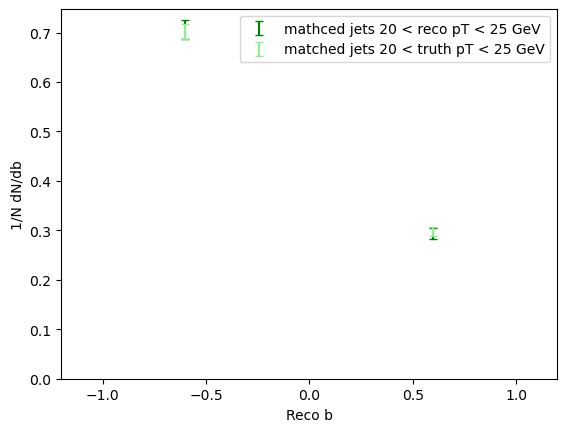

In [38]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
plt.errorbar(x, y_match_pts20/sum(y_match_pts20), yerr=yerr_match_pts20/sum(y_match_pts20), capsize=3, color='g', label='mathced jets 20 < reco pT < 25 GeV', ls='none')
plt.errorbar(x, y_match_pt20/sum(y_match_pt20), yerr=yerr_match_pt20/sum(y_match_pt20), capsize=3, color='lightgreen', label='matched jets 20 < truth pT < 25 GeV', ls='none')
plt.legend()
plt.xlabel('Reco '+ob)
plt.ylabel('1/N dN/d'+ob)
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)

In [42]:
print(y_match_pts20/sum(y_match_pts20), yerr_match_pts20/sum(y_match_pts20))
print(y_match_pt20/sum(y_match_pt20), yerr_match_pt20/sum(y_match_pt20))

[0.70636007 0.29363993] [0.0189809  0.01136867]
[0.70173958 0.29826042] [0.01564226 0.00932272]


In [39]:
(y_match_pt20/sum(y_match_pt20))/(y_match_pts20/sum(y_match_pts20))

array([0.99345873, 1.01573522])

In [79]:
df_match_pts25 = applyCut(df_match, '25 < pts < 30')
df_match_pt25 = applyCut(df_match, '25 < pt < 30')
y_match_pts25,yerr_match_pts25,x = calc_hist(df_match_pts25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts25['w'])
y_match_pt25,yerr_match_pt25,x = calc_hist(df_match_pt25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pt25['w'])

In [80]:
print(y_match_pts25/sum(y_match_pts25), yerr_match_pts25/sum(y_match_pts25))
print(y_match_pt25/sum(y_match_pt25), yerr_match_pt25/sum(y_match_pt25))

[0.69049691 0.30950309] [0.01834966 0.0118916 ]
[0.68946964 0.31053036] [0.01453548 0.00902683]


(0.0, 0.7294083155665911)

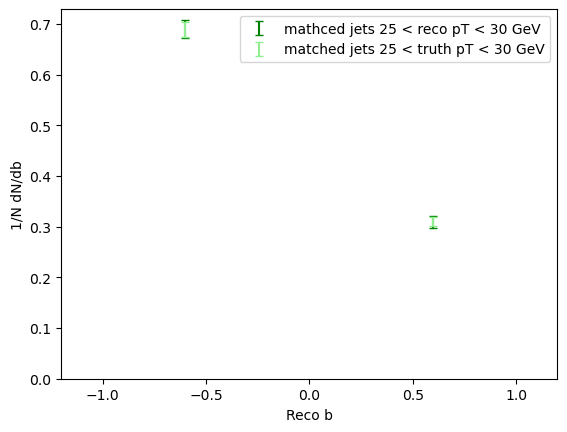

In [106]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
plt.errorbar(x, y_match_pts25/sum(y_match_pts25), yerr=yerr_match_pts25/sum(y_match_pts25), capsize=3, color='g', label='mathced jets 25 < reco pT < 30 GeV', ls='none')
plt.errorbar(x, y_match_pt25/sum(y_match_pt25), yerr=yerr_match_pt25/sum(y_match_pt25), capsize=3, color='lightgreen', label='matched jets 25 < truth pT < 30 GeV', ls='none')
plt.legend()
plt.xlabel('Reco '+ob)
plt.ylabel('1/N dN/d'+ob)
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)

In [107]:
(y_match_pt25/sum(y_match_pt25))/(y_match_pts25/sum(y_match_pts25))

array([0.99851228, 1.00331908])

In [82]:
df_match_pts30 = applyCut(df_match, '30 < pts < 40')
df_match_pt30 = applyCut(df_match, '30 < pt < 40')
y_match_pts30,yerr_match_pts30,x = calc_hist(df_match_pts30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts30['w'])
y_match_pt30,yerr_match_pt30,x = calc_hist(df_match_pt30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pt30['w'])

In [83]:
print(y_match_pts30/sum(y_match_pts30), yerr_match_pts30/sum(y_match_pts30))
print(y_match_pt30/sum(y_match_pt30), yerr_match_pt30/sum(y_match_pt30))

[0.70483795 0.29516205] [0.02715301 0.01526591]
[0.68717103 0.31282897] [0.01796522 0.01489222]


(0.0, 0.7545957085052475)

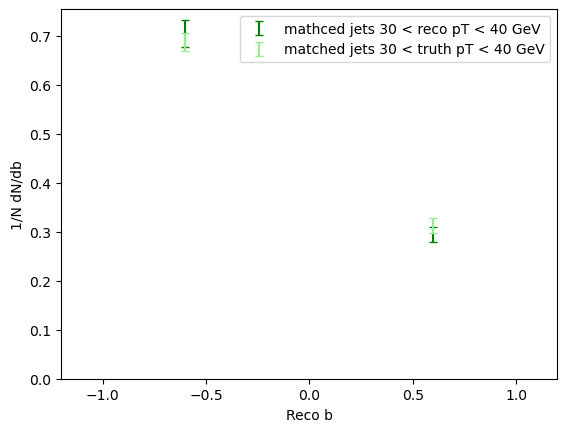

In [109]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
plt.errorbar(x, y_match_pts30/sum(y_match_pts30), yerr=yerr_match_pts30/sum(y_match_pts30), capsize=3, color='g', label='mathced jets 30 < reco pT < 40 GeV', ls='none')
plt.errorbar(x, y_match_pt30/sum(y_match_pt30), yerr=yerr_match_pt30/sum(y_match_pt30), capsize=3, color='lightgreen', label='matched jets 30 < truth pT < 40 GeV', ls='none')
plt.legend()
plt.xlabel('Reco '+ob)
plt.ylabel('1/N dN/d'+ob)
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)

In [110]:
(y_match_pt30/sum(y_match_pt30))/(y_match_pts30/sum(y_match_pts30))

array([0.97493477, 1.059855  ])

relax track matching

In [182]:
df = applyCut(df, 'distance1 < 0.05 and distance2 < 0.05')

In [183]:
rc_00 = getRc(applyCut(df,'15<pt<20'))
rc_err_00 = getRcErr(applyCut(df,'15<pt<20'))

In [184]:
rc_0 = getRc(applyCut(df,'20<pt<25'))
rc_err_0 = getRcErr(applyCut(df,'20<pt<25'))

In [185]:
rc_1 = getRc(applyCut(df,'25<pt<30'))
rc_err_1 = getRcErr(applyCut(df,'25<pt<30'))

In [186]:
rc_2 = getRc(applyCut(df,'30<pt<40'))
rc_err_2 = getRcErr(applyCut(df,'30<pt<40'))

In [187]:
rcs_00 = getRcs(applyCut(df,'15<pt<20'))
rcs_err_00 = getRcsErr(applyCut(df,'15<pt<20'))

In [188]:
rcs_0 = getRcs(applyCut(df,'20<pt<25'))
rcs_err_0 = getRcsErr(applyCut(df,'20<pt<25'))

In [189]:
rcs_1 = getRcs(applyCut(df,'25<pt<30'))
rcs_err_1 = getRcsErr(applyCut(df,'25<pt<30'))

In [190]:
rcs_2 = getRcs(applyCut(df,'30<pt<40'))
rcs_err_2 = getRcsErr(applyCut(df,'30<pt<40'))

Text(0.5, 1.0, 'Matching cut: truth pT > 15 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.05')

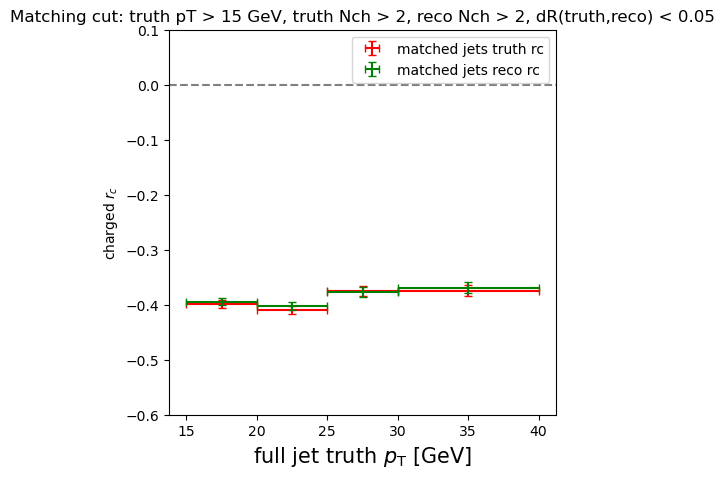

In [191]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00, rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00, rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='matched jets truth rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00, rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='matched jets reco rc')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,0.1)
plt.legend()
plt.title('Matching cut: truth pT > 15 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.05')

In [147]:
rc_00 = getRc(applyCut(df,'15<pts<20'))
rc_err_00 = getRcErr(applyCut(df,'15<pts<20'))

In [148]:
rc_0 = getRc(applyCut(df,'20<pts<25'))
rc_err_0 = getRcErr(applyCut(df,'20<pts<25'))

In [149]:
rc_1 = getRc(applyCut(df,'25<pts<30'))
rc_err_1 = getRcErr(applyCut(df,'25<pts<30'))

In [150]:
rc_2 = getRc(applyCut(df,'30<pts<40'))
rc_err_2 = getRcErr(applyCut(df,'30<pts<40'))

In [151]:
rcs_00 = getRcs(applyCut(df,'15<pts<20'))
rcs_err_00 = getRcsErr(applyCut(df,'15<pts<20'))

In [152]:
rcs_0 = getRcs(applyCut(df_match,'20<pts<25'))
rcs_err_0 = getRcsErr(applyCut(df_match,'20<pts<25'))

In [153]:
rcs_1 = getRcs(applyCut(df,'25<pts<30'))
rcs_err_1 = getRcsErr(applyCut(df,'25<pts<30'))

In [154]:
rcs_2 = getRcs(applyCut(df,'30<pts<40'))
rcs_err_2 = getRcsErr(applyCut(df,'30<pts<40'))

In [155]:
rcs_00_allreco = getRcs(applyCut(df_allreco,'15<pts<20'))
rcs_err_00_allreco = getRcsErr(applyCut(df_allreco,'15<pts<20'))

In [156]:
rcs_0_allreco = getRcs(applyCut(df_allreco,'20<pts<25'))
rcs_err_0_allreco = getRcsErr(applyCut(df_allreco,'20<pts<25'))

In [157]:
rcs_1_allreco = getRcs(applyCut(df_allreco,'25<pts<30'))
rcs_err_1_allreco = getRcsErr(applyCut(df_allreco,'25<pts<30'))

In [158]:
rcs_2_allreco = getRcs(applyCut(df_allreco,'30<pts<40'))
rcs_err_2_allreco = getRcsErr(applyCut(df_allreco,'30<pts<40'))

Text(0.5, 1.0, 'Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.05')

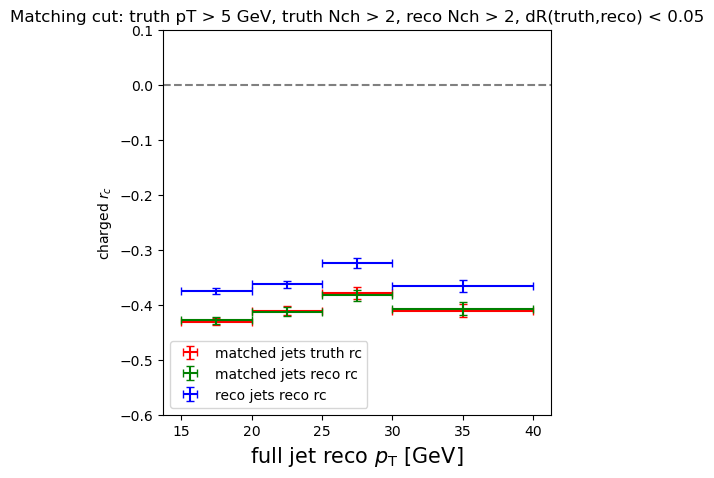

In [161]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00, rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00, rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='matched jets truth rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00, rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='matched jets reco rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00_allreco, rcs_0_allreco, rcs_1_allreco, rcs_2_allreco], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00_allreco, rcs_err_0_allreco, rcs_err_1_allreco, rcs_err_2_allreco], capsize=3, color='b', ls='none', label='reco jets reco rc')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,0.1)
plt.legend()
plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.05')